In [1]:
import argparse
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

def load_curve(run_dir: Path, client: str, eval_name: str):
    """Load pre/post metrics for one run directory."""
    xs = []
    ys = []
    rounds = sorted(
        (run_dir / "eval_rounds").glob("round_*"),
        key=lambda p: int(p.name.split("_")[1]),
    )
    for rpath in rounds:
        rid = int(rpath.name.split("_")[1])
        if client == 'server_post_agg':
            fpath = rpath / f"{client}" / "TOFU_EVAL.json"
        else:
            fpath = rpath / f"{client}_{"post_train"}" / "TOFU_EVAL.json"
        if not fpath.exists():
            print(fpath)
            continue
        try:
            payload = json.loads(fpath.read_text())
        except json.JSONDecodeError:
            continue
        if eval_name not in payload:
            continue
        xs.append(rid)
        ys.append(payload[eval_name]["agg_value"])
    return xs, ys

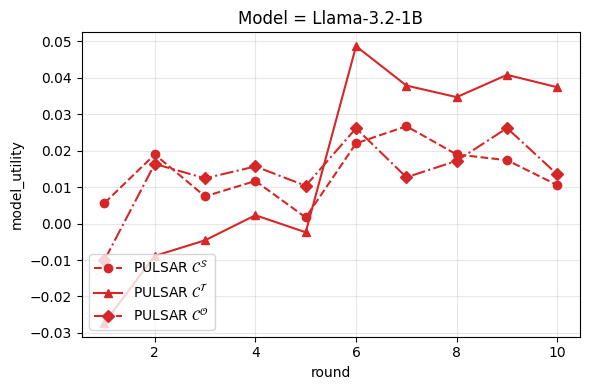

In [5]:
method = "fedperm_only"
retain_split = "retain90"
fl_method = "FedAvg"
ul_method = "GradAscent"
# ul_method = "SimNPO"
epoch = 1
ce0 = 1
alpha = 1
source_client = "client0"
target_client = "client1"
other_client = "client2"
# eval_name = "ra_Q_A_Prob"
eval_name = "model_utility"
# eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"
# models = ["Qwen2.5-1.5B", "Qwen2.5-3B", "Qwen2.5-7B", "Llama-3.2-1B", "Llama-3.2-3B", 
models = ["Llama-3.2-1B"]

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

for model_i in range(len(models)):
    runs = {
        "Finetune": method_root / f"full_{fl_method}_{models[model_i]}-Instruct-lora_{retain_split}",
        "Retain": method_root / f"retain_{fl_method}_{models[model_i]}-Instruct-lora_{retain_split}",
        "PULSAR": method_root / f"unlearn_{fl_method}_{models[model_i]}-Instruct-lora_{retain_split}_{ul_method}_fliter_DCE",
    }

    colors = {
        "Finetune": "#1f77b4",
        "Retain": "#2ca02c",
        "PULSAR": "#d62728"
    }
    linestyles = {"source": "--", "target": "-", "other": "-."}

    fig, ax = plt.subplots(figsize=(6, 4))
    for name, path in runs.items():
        if not path.exists():
            print(path)
            continue
        if not (name == "PULSAR"):
            xs, ys = load_curve(path, client=target_client, eval_name=eval_name)
            if name == "Finetune":
                ys2 = np.array(ys[10:])
            elif name == "Retain":
                ys3 = np.array(ys[10:])

        if name == "PULSAR":
            xs, ys = load_curve(path, client=source_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            ax.plot(
                xs,
                ys-ys3,
                label=f"{name} " + r'$\mathcal{C}^\mathcal{S}$',
                color=colors.get(name),
                linestyle=linestyles["source"],
                marker="o",
            )
        if name == "PULSAR":
            xs, ys = load_curve(path, client=target_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            ax.plot(
                xs,
                ys-ys3,
                label=f"{name} " + r'$\mathcal{C}^\mathcal{T}$',
                color=colors.get(name),
                linestyle=linestyles["target"],
                marker="^",
            )

        # else:
        #     ax.plot(
        #         xs,
        #         ys,
        #         label=f"{name}",
        #         color=colors.get(name),
        #         linestyle=linestyles["target"]
        #     )

        if name == "PULSAR":
            xs, ys = load_curve(path, client=other_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            ax.plot(
                xs,
                ys-ys3,
                label=f"{name} " + r'$\mathcal{C}^\mathcal{O}$',
                color=colors.get(name),
                linestyle=linestyles["other"],
                marker="D",
            )
    # ax.vlines(11, 0, 0.22, colors="black", linestyles='dashed')
    # ax.vlines(15, 0, 0.22, colors="black", linestyles='dashed')
    # ax.set_ylim(ymin=0)
    ax.set_xlabel("round")
    ax.set_ylabel(eval_name)
    ax.set_title(f"Model = {models[model_i]}")
    handles, labels = ax.get_legend_handles_labels()
    if labels:
        ax.legend(loc=3)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    out = f"{retain_split}_{fl_method}_{ul_method}_{models[model_i]}_{eval_name}.eps"
    # plt.savefig(out, dpi=200)
    # print(f"Saved plot to {out}")
    plt.show()